# Population and RDM drift — all voxels vs matched voxel count (SP)

Reads the outputs of `SP_Model/6_save_perm_pop_expand.ipynb` run twice: with all voxels (`repDrift_expand/`) and with `MATCH_VOX = True` (`repDrift_expand/matchVox/`, every ROI subsampled to the subject's smallest ROI, one seeded draw). Nothing is recomputed except the summary statistics.

- **Drift strength** per subject: Roth-style correlation between the session × session matrix and session lag (off-diagonal entries), signed so that **positive = more drift** (−r for similarity measures: population correlation, RDM Spearman; +r for RMSE distances).
- **Group test:** mean over subjects, compared with the same statistic on the saved session-order permutations (identical permutation orders in every file), one-sided.
- **Between-ROI test** on the matched data: Friedman across the 4 ROIs and pairwise Wilcoxon (per-subject drift strength, n = 8; uncorrected — the reported analysis remains the hierarchy scripts with FDR correction).
- `MODEL = "Ori"` uses the full SP model (4 ori × 4 SF + low/high-pass); set `ZSTR` to the normalization used in notebook 6.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# ==== Configuration ====
import os, numpy as np, matplotlib.pyplot as plt
from scipy.stats import friedmanchisquare, wilcoxon
from itertools import combinations

BASE   = "/content/drive/MyDrive/V1_Drift/repDrift_expand/"     # no-background SP config
ZSTR   = ""        # normalization suffix used in notebook 6: "" (DEFAULT_TO_ZSCORE=0), "_equalStd" (3), ...
NPERMS = 1000
OUT    = "/content/drive/MyDrive/V1_Drift/plots/population_rdm_matched/"
ROIS   = {1: "V1", 2: "V2", 3: "V3", 4: "hV4"}
SUBJECTS = range(1, 9)
MODEL  = "Ori"     # "Ori" = full SP model (4 ori x 4 SF + low/high-pass, 18 predictors); "" = SF-levels-only model
# (level name, RDM file tag, matrix key, permutation key, similarity?)  similarity: drift = decrease with lag
LEVELS = [
    ("population",          "rdmCorrDist_cmpSpearman",  "avgImgCorrMat",   "imgCorrMatPerm",      True),
    ("RDM 1-r / Spearman",  "rdmCorrDist_cmpSpearman",  "betweenSessCorr", "betweenSessCorrPerm", True),
    ("RDM 1-r / RMSE",      "rdmCorrDist_cmpRMSE",      "betweenSessCorr", "betweenSessCorrPerm", False),
    ("RDM Eucl / Spearman", "rdmEuclidean_cmpSpearman", "betweenSessCorr", "betweenSessCorrPerm", True),
    ("RDM Eucl / RMSE",     "rdmEuclidean_cmpRMSE",     "betweenSessCorr", "betweenSessCorrPerm", False),
]


In [3]:
# ==== Functions ====
def path(vreg, s, tag, matched):
    return os.path.join(BASE, "matchVox" if matched else "", f"permPop_N{NPERMS}_v{vreg}_sub{s}{ZSTR}_{tag}.npz")

def drift_strength(M):
    """Roth-style lag correlation over off-diagonal entries; returned as DRIFT STRENGTH
    (positive = more drift): -r for similarity measures, +r for distance (RMSE) measures."""
    ns = M.shape[0]; lag = np.abs(np.subtract.outer(np.arange(ns), np.arange(ns))); off = lag > 0
    return np.corrcoef(M[off], lag[off])[0, 1]

def load_level(level, matched):
    name, tag, key, pkey, is_sim = level
    sign = -1.0 if is_sim else 1.0
    obs, null, nvox, missing = {}, {}, {}, []
    for vreg, roi in ROIS.items():
        o, n, v = [], [], []
        for s in SUBJECTS:
            fn = path(vreg, s, tag, matched)
            if not os.path.exists(fn): missing.append(f"{roi} S{s}"); continue
            d = np.load(fn, allow_pickle=True)
            M, P = d[key + MODEL], d[pkey.replace("Perm", MODEL + "Perm")]
            o.append(sign * drift_strength(M))
            n.append(np.array([sign * drift_strength(P[i]) for i in range(P.shape[0])]))
            v.append(int(d["numGoodVox"]))
        if o:
            obs[roi], null[roi], nvox[roi] = np.array(o), np.array(n), v
    return obs, null, nvox, missing

def summarize(level, matched):
    obs, null, nvox, missing = load_level(level, matched)
    out = {}
    for roi in obs:
        g_obs = obs[roi].mean(); g_null = null[roi].mean(0)          # same permutation orders in every file (seed 1)
        out[roi] = dict(drift=g_obs, p=(np.sum(g_null >= g_obs) + 1) / (len(g_null) + 1),
                        subj=obs[roi], n=len(obs[roi]), vox=int(np.median(nvox[roi])))
    return out, missing


## All voxels vs matched

In [4]:
# ==== All voxels vs matched voxel count, per level ====
results = {}
for level in LEVELS:
    for matched in (False, True):
        res, missing = summarize(level, matched)
        results[(level[0], matched)] = res
        if missing: print(f"[{level[0]}, {'matched' if matched else 'all'}] missing files: {missing[:6]}{' ...' if len(missing) > 6 else ''}")

print(f"\nDrift strength (positive = more drift; -r for similarity, +r for RMSE), mean over subjects; "
      f"p = session-order permutation (one-sided); model = SP{' ' + MODEL if MODEL else ''}\n")
print(f"{'level':22s} " + "  ".join(f"{r:>24s}" for r in ROIS.values()))
print(f"{'':22s} " + "  ".join(f"{'all -> matched (vox)':>24s}" for _ in ROIS))
for level in LEVELS:
    a, m = results[(level[0], False)], results[(level[0], True)]
    cells = []
    for roi in ROIS.values():
        if roi in a and roi in m:
            st = lambda x: "*" if x["p"] < 0.05 else " "
            cells.append(f"{a[roi]['drift']:+.3f}{st(a[roi])} -> {m[roi]['drift']:+.3f}{st(m[roi])} ({m[roi]['vox']})")
        else: cells.append("n/a")
    print(f"{level[0]:22s} " + "  ".join(f"{c:>24s}" for c in cells))
print("\n* = p < 0.05")



Drift strength (positive = more drift; -r for similarity, +r for RMSE), mean over subjects; p = session-order permutation (one-sided); model = SP Ori

level                                        V1                        V2                        V3                       hV4
                           all -> matched (vox)      all -> matched (vox)      all -> matched (vox)      all -> matched (vox)
population             +0.205* -> +0.250* (480)  +0.272* -> +0.252* (480)  +0.229* -> +0.194* (480)  +0.160* -> +0.160* (480)
RDM 1-r / Spearman     +0.091* -> +0.073* (480)  +0.080* -> +0.067* (480)  +0.068* -> +0.053  (480)  +0.083* -> +0.083* (480)
RDM 1-r / RMSE         +0.204* -> +0.184* (480)  +0.182* -> +0.191* (480)  +0.147* -> +0.162* (480)  +0.139* -> +0.139* (480)
RDM Eucl / Spearman    +0.031  -> +0.036  (480)  +0.069* -> +0.050  (480)  +0.047  -> +0.034  (480)  +0.052* -> +0.052* (480)
RDM Eucl / RMSE        +0.219* -> +0.223* (480)  +0.231* -> +0.217* (480)  +0.161* -> +0.154

## Between-ROI comparison (matched voxel count)

In [5]:
# ==== Between-ROI comparison on the matched data (per-subject drift strength, n = 8) ====
for level in LEVELS:
    m = results[(level[0], True)]
    if len(m) < 4 or len({m[r]['n'] for r in m}) != 1:
        print(f"{level[0]}: incomplete, skipped"); continue
    D = {r: m[r]["subj"] for r in ROIS.values()}
    print(f"\n{level[0]}   Friedman p = {friedmanchisquare(*D.values()).pvalue:.4f}")
    print("   per subject: " + " | ".join(f"{r} " + " ".join(f"{x:+.2f}" for x in D[r]) for r in D))
    for a, b in combinations(D, 2):
        d = D[a] - D[b]
        print(f"   {a:4s} vs {b:4s}: mean diff {d.mean():+.3f}  Wilcoxon p = {wilcoxon(d).pvalue:.3f}  "
              f"({(d > 0).sum()}/{len(d)} subjects more drift in {a})")



population   Friedman p = 0.0503
   per subject: V1 +0.36 +0.16 +0.28 +0.35 +0.07 +0.22 +0.30 +0.26 | V2 +0.31 +0.25 +0.28 +0.15 +0.23 +0.22 +0.35 +0.23 | V3 +0.27 +0.15 +0.08 +0.14 +0.13 +0.20 +0.33 +0.25 | hV4 +0.31 +0.01 +0.09 +0.23 +0.10 +0.05 +0.31 +0.19
   V1   vs V2  : mean diff -0.002  Wilcoxon p = 0.844  (4/8 subjects more drift in V1)
   V1   vs V3  : mean diff +0.056  Wilcoxon p = 0.250  (6/8 subjects more drift in V1)
   V1   vs hV4 : mean diff +0.090  Wilcoxon p = 0.039  (6/8 subjects more drift in V1)
   V2   vs V3  : mean diff +0.058  Wilcoxon p = 0.039  (7/8 subjects more drift in V2)
   V2   vs hV4 : mean diff +0.092  Wilcoxon p = 0.055  (7/8 subjects more drift in V2)
   V3   vs hV4 : mean diff +0.034  Wilcoxon p = 0.383  (5/8 subjects more drift in V3)

RDM 1-r / Spearman   Friedman p = 0.8964
   per subject: V1 -0.04 -0.01 +0.20 +0.04 -0.01 +0.07 +0.08 +0.25 | V2 -0.01 +0.06 +0.18 +0.04 +0.07 +0.08 -0.03 +0.15 | V3 -0.01 +0.02 +0.27 -0.03 +0.06 -0.05 -0.00 +0.17 | 

## Plot

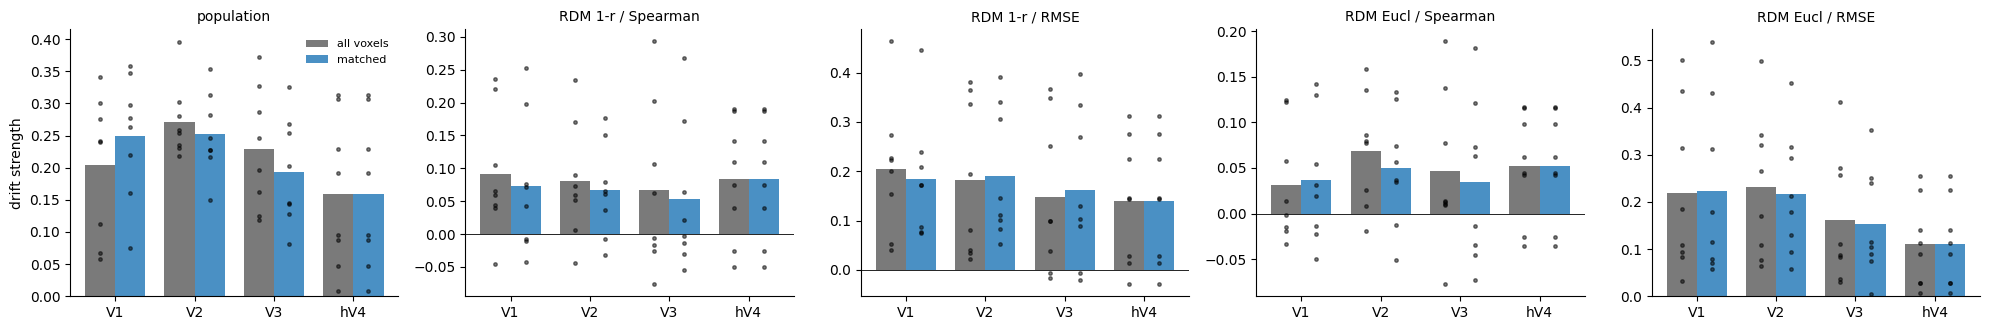

In [6]:
# ==== Plot: drift strength per ROI, all vs matched ====
fig, axs = plt.subplots(1, len(LEVELS), figsize=(4 * len(LEVELS), 3.4), sharey=False)
x = np.arange(len(ROIS))
for ax, level in zip(axs, LEVELS):
    for k, (matched, col, lab) in enumerate([(False, "#7a7a7a", "all voxels"), (True, "#4a90c4", "matched")]):
        r = results[(level[0], matched)]
        mu = [r[roi]["drift"] if roi in r else np.nan for roi in ROIS.values()]
        ax.bar(x + (k - 0.5) * 0.38, mu, 0.38, color=col, label=lab)
        for i, roi in enumerate(ROIS.values()):
            if roi in r: ax.plot(np.full(r[roi]["n"], x[i] + (k - 0.5) * 0.38), r[roi]["subj"], "o", ms=2.5, color="k", alpha=0.5)
    ax.axhline(0, color="k", lw=0.6); ax.set_xticks(x); ax.set_xticklabels(list(ROIS.values()))
    ax.set_title(level[0], fontsize=10)
    for side in ["top", "right"]: ax.spines[side].set_visible(False)
axs[0].set_ylabel("drift strength"); axs[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); os.makedirs(OUT, exist_ok=True); plt.savefig(OUT + f"population_rdm_all_vs_matched{ZSTR}.png", dpi=200); plt.show()
